# NHANES — CNN 1D với 4 chỉ số

NHANES Hoa Kỳ, nhãn tự khai DIQ010 về chẩn đoán đã biết; glucose và HbA1c cùng thời điểm có thể gắn với việc chẩn đoán hoặc điều trị.

Chạy lần lượt từ trên xuống. Notebook tự tạo thư mục kết quả mới; không thay đổi mô hình của website. Kết quả chỉ dùng cho học thuật.

## 1. Thiết lập
Chọn dữ liệu, cấu hình và đường dẫn. Mỗi lần chạy tạo một thư mục mới trong `artifacts/notebook_runs/`.

In [1]:
EXPERIMENT = 'nhanes4'
MODEL_TYPE = 'CNN'
PURPOSE = 'NHANES Hoa Kỳ, nhãn tự khai DIQ010 về chẩn đoán đã biết; glucose và HbA1c cùng thời điểm có thể gắn với việc chẩn đoán hoặc điều trị.'
import os, json, hashlib, random, sys, platform
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, brier_score_loss)
import torch
from torch import nn
import joblib
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'docker-compose.yml').exists()), None)
if ROOT is None: raise RuntimeError('Chạy notebook trong thư mục dự án.')
SMOKE = os.getenv('NOTEBOOK_SMOKE') == '1'  # Chỉ dùng cho kiểm thử kỹ thuật, không báo cáo kết quả.
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(1)
run_stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
RUN_DIR = (Path('/tmp/duongan_notebook_smoke') if SMOKE else ROOT/'artifacts/notebook_runs') / EXPERIMENT / run_stamp
RUN_DIR.mkdir(parents=True, exist_ok=False)
print('Project:', ROOT, '| kết quả:', RUN_DIR, '| kiểm thử nhanh:', SMOKE)

Project: /app | kết quả: /app/artifacts/notebook_runs/nhanes4/20261105T081915_164118Z | kiểm thử nhanh: False


## 2. Đọc và biểu diễn dữ liệu
Đọc dữ liệu gốc và kiểm tra số dòng, cột. Các biểu đồ phân tích chi tiết ở mục 4 chỉ dùng tập train.

In [2]:
features = ['RIDAGEYR','BMXBMI','LBXGLU','LBXGH']
numeric, categorical = features, []
columns = {
 'DEMO':['SEQN','RIDAGEYR','RIAGENDR','SDMVSTRA','SDMVPSU'], 'DIQ':['SEQN','DIQ010'],
 'BMX':['SEQN','BMXBMI','BMXWAIST','BMXWT','BMXHT'], 'BPX':['SEQN','BPXSY1','BPXDI1'],
 'GLU':['SEQN','LBXGLU'], 'GHB':['SEQN','LBXGH'], 'TCHOL':['SEQN','LBXTC'],
 'HDL':['SEQN','LBDHDD'], 'TRIGLY':['SEQN','LBXTR'], 'BIOPRO':['SEQN','LBXSATSI','LBXSCR']}
# Chỉ đọc tệp cần thiết cho các biến được chọn.
columns = {k:v for k,v in columns.items() if k in ('DEMO','DIQ') or set(v[1:]) & set(features)}
source_paths = []
def read_cycle(suffix):
    frames=[]
    for name, cols in columns.items():
        path=ROOT/f'data/raw/nhanes/{name}_{suffix}.xpt'; source_paths.append(path)
        f=pd.read_sas(path,format='xport')[cols]
        if f.SEQN.duplicated().any(): raise ValueError(f'Trùng SEQN: {path}')
        frames.append(f)
    df=frames[0]
    for f in frames[1:]: df=df.merge(f,on='SEQN',how='left',validate='one_to_one')
    return df
raw = [read_cycle('I'), read_cycle('J')]
print('Số dòng gốc 2015–16/2017–18:',[len(x) for x in raw])

Số dòng gốc 2015–16/2017–18: [9971, 9254]


## 3. Làm sạch, định nghĩa nhãn và chia tập
Loại nhãn không hợp lệ, kiểm soát dữ liệu thiếu và tách test. Các phép học tham số xử lý dữ liệu chỉ được fit sau khi chia tập.

In [3]:
def clean_cycle(raw):
    df=raw[(raw.RIDAGEYR>=18)&raw.DIQ010.isin([1,2])].copy()
    for col in ['BPXSY1','BPXDI1']:
        if col in df: df.loc[df[col] <= 0,col] = np.nan
    df = df.dropna(subset=features+['SDMVSTRA','SDMVPSU']).copy()
    df['class'] = (df.DIQ010 == 1).astype(int)
    df['group'] = df.SDMVSTRA.astype(str)+'_'+df.SDMVPSU.astype(str)
    return df
old, test = [clean_cycle(frame) for frame in raw]
if set(old.SEQN)&set(test.SEQN): raise ValueError('SEQN trùng giữa các chu kỳ; cần kiểm tra.')
indices = GroupShuffleSplit(n_splits=1,test_size=0.2,random_state=SEED)
a,b = next(indices.split(old,old['class'],groups=old.group))
train,val = old.iloc[a].copy(),old.iloc[b].copy()
assert set(train.group).isdisjoint(set(val.group))
print('Mẫu đủ dữ liệu chu kỳ train/test:',len(old),len(test))

Mẫu đủ dữ liệu chu kỳ train/test: 2485 2408


## 4. Biểu diễn và phân tích dữ liệu train
Kiểm tra phân bố nhãn, thiếu dữ liệu, thống kê, histogram theo nhãn và tương quan các biến số. Mẫu hiển thị có thể được giới hạn để vẽ nhanh; huấn luyện dùng toàn bộ tập train.

train: 1976 mẫu; nhãn: {0: 1687, 1: 289}
validation: 509 mẫu; nhãn: {0: 424, 1: 85}
test: 2408 mẫu; nhãn: {0: 2003, 1: 405}

Thiếu dữ liệu trên train (%):
RIDAGEYR    0.0
BMXBMI      0.0
LBXGLU      0.0
LBXGH       0.0

Thống kê biến số trên train:
       RIDAGEYR   BMXBMI   LBXGLU    LBXGH
count   1976.00  1976.00  1976.00  1976.00
mean      48.07    29.11   112.49     5.83
std       18.36     6.98    40.88     1.23
min       18.00    15.10    50.00     4.00
25%       33.00    24.20    95.00     5.30
50%       48.00    28.10   102.00     5.50
75%       63.00    32.72   112.00     5.90
max       80.00    64.50   479.00    17.00


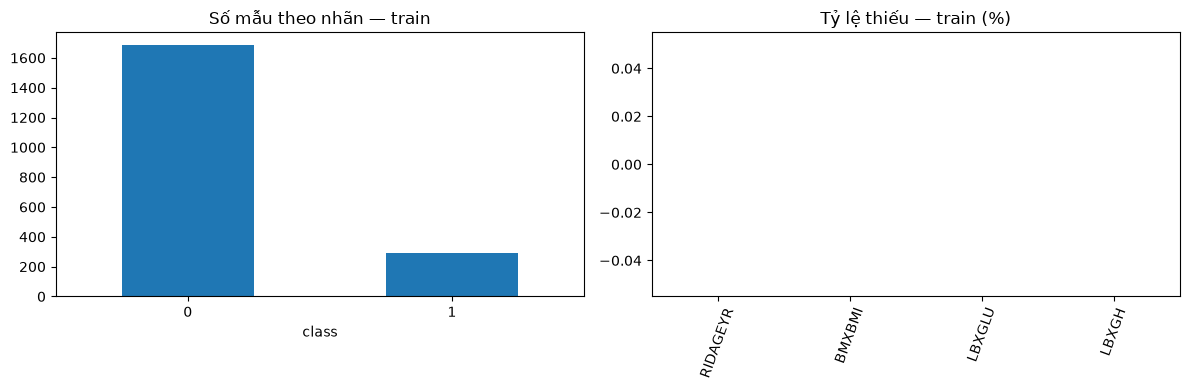

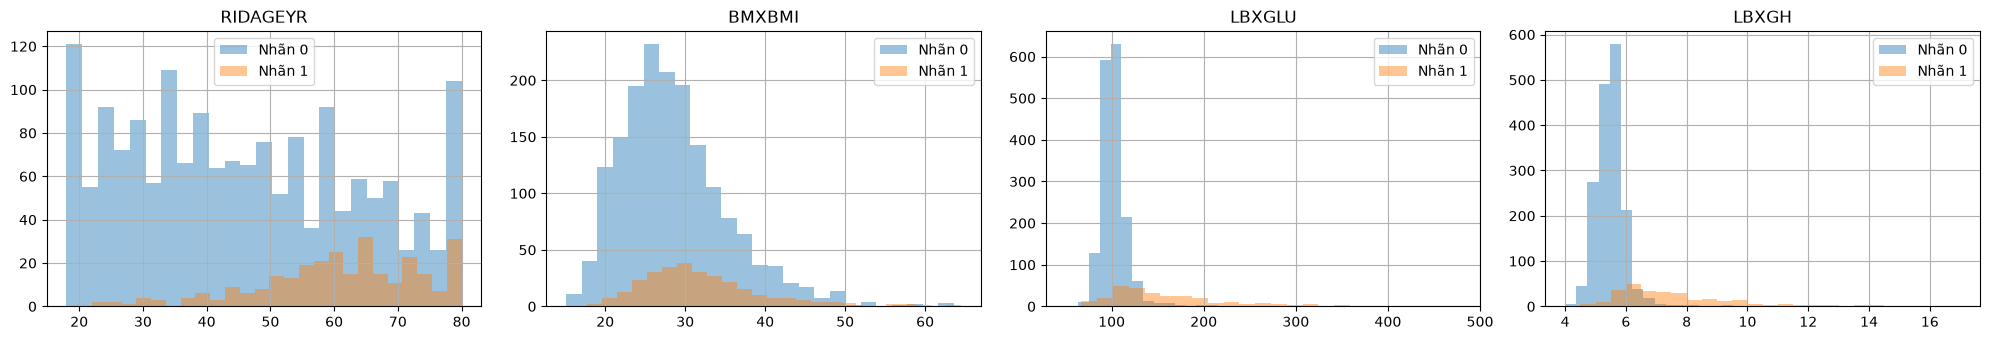

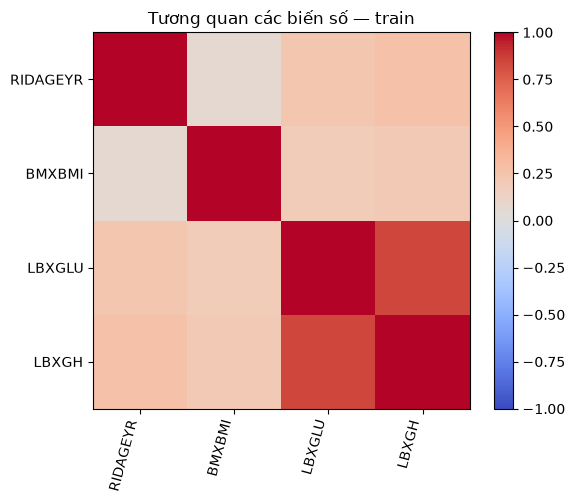

In [4]:
# Phân tích trên tập train để không dùng test quyết định đặc trưng.
for name, frame in [('train',train),('validation',val),('test',test)]:
    counts = frame['class'].value_counts().sort_index().to_dict()
    print(f'{name}: {len(frame)} mẫu; nhãn: {counts}')
    if frame['class'].nunique() != 2: raise ValueError(f'{name} cần đủ hai lớp')
print('\nThiếu dữ liệu trên train (%):')
print((train[features].isna().mean().sort_values(ascending=False)*100).round(2).to_string())
print('\nThống kê biến số trên train:')
print(train[numeric].describe().round(2).to_string())
fig,axes=plt.subplots(1,2,figsize=(12,4))
train['class'].value_counts().sort_index().plot.bar(ax=axes[0],title='Số mẫu theo nhãn — train',rot=0)
(train[features].isna().mean()*100).sort_values(ascending=False).head(12).plot.bar(ax=axes[1],title='Tỷ lệ thiếu — train (%)',rot=70)
plt.tight_layout(); plt.show()
# Số mẫu lớn chỉ lấy tối đa 10.000 điểm train cho biểu đồ, không thay đổi dữ liệu huấn luyện.
visual=train.sample(n=min(10000,len(train)),random_state=SEED)
plot_cols=numeric[:min(4,len(numeric))]
fig,axes=plt.subplots(1,len(plot_cols),figsize=(5*len(plot_cols),3.5),squeeze=False)
for ax,col in zip(axes[0],plot_cols):
    for label in (0,1):
        visual.loc[visual['class']==label,col].dropna().hist(ax=ax,bins=25,alpha=.45,label=f'Nhãn {label}')
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()
if len(numeric)>1:
    corr=visual[numeric].corr(numeric_only=True)
    fig,ax=plt.subplots(figsize=(max(6,len(corr)*.65),max(5,len(corr)*.65)))
    im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
    ax.set_xticks(range(len(corr)),corr.columns,rotation=75,ha='right'); ax.set_yticks(range(len(corr)),corr.index)
    ax.set_title('Tương quan các biến số — train'); fig.colorbar(im,ax=ax); plt.tight_layout(); plt.show()

## 5. Tiền xử lý
Điền khuyết và chuẩn hóa trên train; biến phân loại one-hot. Áp dụng các phép biến đổi đã học lên validation/test.

In [5]:
def frame_x(frame):
    x=frame[features].copy()
    for col in categorical: x[col]=x[col].astype(object).where(x[col].notna(),np.nan)
    return x
parts=[]
if numeric: parts.append(('num',make_pipeline(SimpleImputer(strategy='median'),StandardScaler()),numeric))
if categorical: parts.append(('cat',make_pipeline(SimpleImputer(strategy='most_frequent'),OneHotEncoder(handle_unknown='ignore')),categorical))
preprocessor=ColumnTransformer(parts,sparse_threshold=0)
Xtr=preprocessor.fit_transform(frame_x(train)).astype('float32')
Xva=preprocessor.transform(frame_x(val)).astype('float32')
Xte=preprocessor.transform(frame_x(test)).astype('float32')
ytr,yva,yte=[f['class'].to_numpy(dtype='float32') for f in (train,val,test)]
print('Kích thước sau tiền xử lý:',Xtr.shape,Xva.shape,Xte.shape)

Kích thước sau tiền xử lý: (1976, 4) (509, 4) (2408, 4)


## 6. Định nghĩa mô hình và baseline
Mạng nơ-ron so sánh với Dummy, Logistic Regression và HistGradientBoosting. CNN 1D trên dữ liệu bảng là giả định thực nghiệm về thứ tự cột.

In [6]:
# So sánh với baseline đơn giản và mô hình phi tuyến trên cùng dữ liệu.
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, roc_curve, precision_recall_curve
class Net(nn.Module):
    def __init__(self,n):
        super().__init__()
        if MODEL_TYPE=='MLP':
            self.net=nn.Sequential(nn.Linear(n,64),nn.ReLU(),nn.Dropout(.2),nn.Linear(64,32),nn.ReLU(),nn.Linear(32,1))
        else:
            self.net=nn.Sequential(nn.Unflatten(1,(1,n)),nn.Conv1d(1,16,3,padding=1),nn.ReLU(),nn.Conv1d(16,32,3,padding=1),nn.ReLU(),nn.MaxPool1d(2),nn.Flatten(),nn.Linear(32*(n//2),32),nn.ReLU(),nn.Dropout(.2),nn.Linear(32,1))
    def forward(self,x): return self.net(x).squeeze(-1)
print('Kiến trúc ứng viên:'); print(Net(Xtr.shape[1]))
print('So sánh thêm: Dummy prior, Logistic Regression, HistGradientBoosting.')

Kiến trúc ứng viên:
Net(
  (net): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(1, 4))
    (1): Conv1d(1, 16, kernel_size=(3,), stride=(1,), padding=(1,))
    (2): ReLU()
    (3): Conv1d(16, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): ReLU()
    (5): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=64, out_features=32, bias=True)
    (8): ReLU()
    (9): Dropout(p=0.2, inplace=False)
    (10): Linear(in_features=32, out_features=1, bias=True)
  )
)
So sánh thêm: Dummy prior, Logistic Regression, HistGradientBoosting.


## 7. Huấn luyện và kiểm tra hội tụ
Tối đa 200 epoch, tối thiểu 40 epoch và dừng sớm nếu validation loss không cải thiện trong 25 epoch. Chạy ba seed khởi tạo; đồ thị hiển thị train/validation loss, epoch tốt nhất và số bước cập nhật. Seed chỉ đo độ nhạy khởi tạo, không thay thế kiểm định trên nhiều tập chia độc lập.

Training dummy


Training logistic_regression


Training hist_gradient_boosting


seed=42: epochs=40, best=13, updates=1240, val AUC=0.9461, early_stop=True


seed=43: epochs=42, best=17, updates=1302, val AUC=0.9484, early_stop=True


seed=44: epochs=46, best=21, updates=1426, val AUC=0.9469, early_stop=True


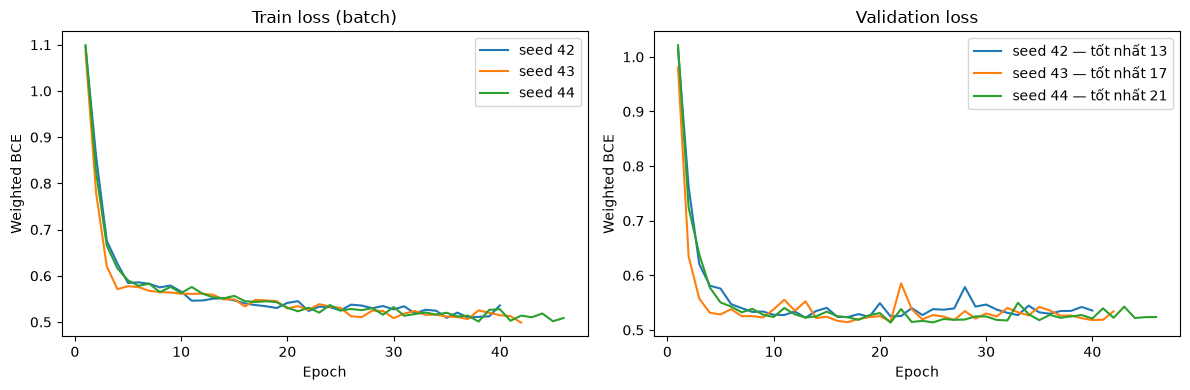

Dao động validation AUC giữa các seed: [0.9461, 0.9484, 0.9469]


In [7]:
# Cùng tập train/validation cho tất cả ứng viên. Ba seed chỉ thay đổi khởi tạo,
# không thay thế việc đánh giá trên nhiều phép chia dữ liệu độc lập.
from copy import deepcopy
candidates = {
    'dummy':DummyClassifier(strategy='prior'),
    'logistic_regression':LogisticRegression(max_iter=1000,class_weight='balanced',random_state=SEED),
    'hist_gradient_boosting':HistGradientBoostingClassifier(max_iter=100 if not SMOKE else 5,max_leaf_nodes=15,class_weight='balanced',random_state=SEED),
}
for name, estimator in candidates.items():
    print('Training',name,flush=True); estimator.fit(Xtr,ytr)

seeds=[42] if SMOKE else [42,43,44]
max_epochs=2 if SMOKE else 200
min_epochs=1 if SMOKE else 40
patience_limit=2 if SMOKE else 25
# Batch lớn giúp bộ BRFSS khả thi; số lần cập nhật thực tế được lưu trong report.
batch_size=4096 if EXPERIMENT=='brfss' else 64
xt,yt=torch.tensor(Xtr),torch.tensor(ytr)
xv,yv=torch.tensor(Xva),torch.tensor(yva)
pos_weight=torch.tensor([(len(ytr)-sum(ytr))/sum(ytr)],dtype=torch.float32)
loss_fn=nn.BCEWithLogitsLoss(pos_weight=pos_weight)
runs=[]
for run_seed in seeds:
    torch.manual_seed(run_seed); random.seed(run_seed); np.random.seed(run_seed)
    model=Net(Xtr.shape[1]); optimizer=torch.optim.Adam(model.parameters(),lr=0.001)
    generator=torch.Generator().manual_seed(run_seed)
    loader=torch.utils.data.DataLoader(torch.utils.data.TensorDataset(xt,yt),batch_size=batch_size,shuffle=True,generator=generator)
    best_loss=float('inf'); best_state=None; best_epoch=0; patience=0; history=[]; updates=0
    for epoch in range(1,max_epochs+1):
        model.train(); total_loss=0.0
        for x,y in loader:
            optimizer.zero_grad(); loss=loss_fn(model(x),y); loss.backward(); optimizer.step()
            total_loss+=float(loss.detach())*len(y); updates+=1
        model.eval()
        with torch.no_grad(): val_loss=float(loss_fn(model(xv),yv))
        history.append({'epoch':epoch,'train_loss':total_loss/len(ytr),'val_loss':val_loss})
        if val_loss < best_loss - 1e-4:
            best_loss=val_loss; best_epoch=epoch; best_state=deepcopy(model.state_dict()); patience=0
        else: patience+=1
        if epoch>=min_epochs and patience>=patience_limit: break
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad(): valid_scores=torch.sigmoid(model(xv)).numpy()
    run={'seed':run_seed,'model':model,'best_epoch':best_epoch,'epochs_run':len(history),
         'updates':updates,'stopped_early':len(history)<max_epochs,'history':history,
         'val_scores':valid_scores,'val_auc':float(roc_auc_score(yva,valid_scores))}
    runs.append(run)
    print(f"seed={run_seed}: epochs={len(history)}, best={best_epoch}, updates={updates}, val AUC={run['val_auc']:.4f}, early_stop={run['stopped_early']}",flush=True)

fig,axes=plt.subplots(1,2,figsize=(12,4))
for run in runs:
    curve=pd.DataFrame(run['history'])
    axes[0].plot(curve.epoch,curve.train_loss,label=f"seed {run['seed']}")
    axes[1].plot(curve.epoch,curve.val_loss,label=f"seed {run['seed']} — tốt nhất {run['best_epoch']}")
for ax,title in zip(axes,['Train loss (batch)','Validation loss']): ax.set_title(title); ax.set_xlabel('Epoch'); ax.set_ylabel('Weighted BCE'); ax.legend()
plt.tight_layout(); plt.show()
print('Dao động validation AUC giữa các seed:',[round(r['val_auc'],4) for r in runs])

## 8. So sánh và lựa chọn trên validation
Bảng so sánh ROC-AUC, PR-AUC, precision, recall, F1; chọn ứng viên theo ROC-AUC validation, sau đó chọn ngưỡng theo F1 validation. Test không tham gia lựa chọn.

Bảng validation (ngưỡng tham khảo 0.5):
                        roc_auc  pr_auc  precision  recall      f1
neural_seed_43           0.9484  0.8177     0.6356  0.8824  0.7389
neural_seed_44           0.9469  0.8071     0.6410  0.8824  0.7426
neural_seed_42           0.9461  0.8063     0.6410  0.8824  0.7426
logistic_regression      0.9450  0.8192     0.5789  0.9059  0.7064
hist_gradient_boosting   0.9268  0.7903     0.6522  0.8824  0.7500
dummy                    0.5000  0.1670     0.0000  0.0000  0.0000


Chọn theo validation ROC-AUC: neural_seed_43 | ngưỡng F1 trên validation: 0.75
 threshold  precision  recall     f1
      0.05     0.2252  0.9882 0.3668
      0.10     0.2763  0.9882 0.4319
      0.15     0.3092  0.9529 0.4669
      0.20     0.3600  0.9529 0.5226
      0.25     0.4444  0.9412 0.6038
      0.30     0.4938  0.9294 0.6449
      0.35     0.5200  0.9176 0.6638
      0.40     0.5612  0.9176 0.6964
      0.45     0.6210  0.9059 0.7368
      0.50     0.6356  0.8824 0.7389
      0.55     0.6881  0.8824 0.7732
      0.60     0.7115  0.8706 0.7831
      0.65     0.7551  0.8706 0.8087
      0.70     0.7708  0.8706 0.8177
      0.75     0.7849  0.8588 0.8202
      0.80     0.8095  0.8000 0.8047
      0.85     0.8533  0.7529 0.8000
      0.90     0.8889  0.6588 0.7568
      0.95     0.8974  0.4118 0.5645


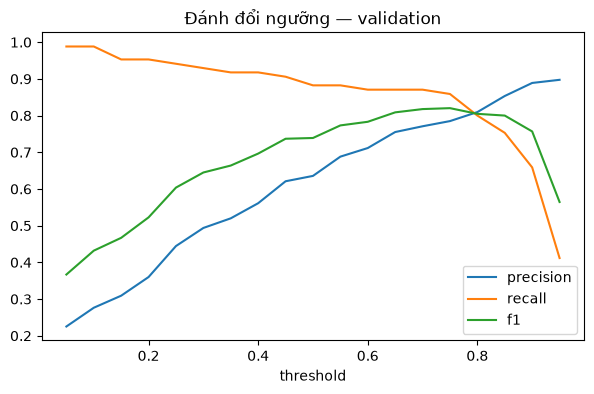

In [8]:
# So sánh validation theo nhiều chỉ số. AUC quyết định mô hình; ngưỡng F1 được chọn riêng trên validation.
val_scores={name:est.predict_proba(Xva)[:,1] for name,est in candidates.items()}
for run in runs: val_scores[f"neural_seed_{run['seed']}"]=run['val_scores']
def threshold_scores(y, scores, threshold):
    pred=(scores>=threshold).astype(int)
    return {'roc_auc':float(roc_auc_score(y,scores)),'pr_auc':float(average_precision_score(y,scores)),
            'precision':float(precision_score(y,pred,zero_division=0)),'recall':float(recall_score(y,pred,zero_division=0)),
            'f1':float(f1_score(y,pred,zero_division=0))}
validation_table=pd.DataFrame({name:threshold_scores(yva,s,.5) for name,s in val_scores.items()}).T.sort_values('roc_auc',ascending=False)
print('Bảng validation (ngưỡng tham khảo 0.5):'); print(validation_table.round(4).to_string())
# Nếu bằng AUC, ưu tiên baseline đơn giản theo thứ tự khai báo.
priority=list(val_scores)
selected=max(priority,key=lambda name:roc_auc_score(yva,val_scores[name]))
threshold_grid=np.round(np.linspace(.05,.95,19),2)
threshold_table=pd.DataFrame([{'threshold':float(t),**threshold_scores(yva,val_scores[selected],t)} for t in threshold_grid])
selected_threshold=float(threshold_table.loc[threshold_table.f1.idxmax(),'threshold'])
print('Chọn theo validation ROC-AUC:',selected,'| ngưỡng F1 trên validation:',selected_threshold)
print(threshold_table[['threshold','precision','recall','f1']].round(4).to_string(index=False))
threshold_table.plot(x='threshold',y=['precision','recall','f1'],title='Đánh đổi ngưỡng — validation',figsize=(7,4));plt.show()
# Ngưỡng F1 là lựa chọn thực nghiệm, không phải ngưỡng lâm sàng.

## 9. Đánh giá test của mô hình đã chọn
Bảng chỉ số, báo cáo phân loại, ROC, Precision–Recall, ma trận nhầm lẫn và khoảng bootstrap phân tầng. Đây là đánh giá học thuật không trọng số; tập test đã từng được sử dụng trong các lần chạy trước và không còn hoàn toàn độc lập.

Kết quả test CHỈ của ứng viên được chọn:
{
  "roc_auc": 0.9490504983265843,
  "pr_auc": 0.8155085225980495,
  "precision": 0.8159340659340659,
  "recall": 0.7333333333333333,
  "f1": 0.7724317295188556,
  "accuracy": 0.9273255813953488,
  "brier": 0.08082994818687439,
  "confusion_matrix": [
    [
      1936,
      67
    ],
    [
      108,
      297
    ]
  ]
}
Báo cáo phân loại:


              precision    recall  f1-score   support

         0.0       0.95      0.97      0.96      2003
         1.0       0.82      0.73      0.77       405

    accuracy                           0.93      2408
   macro avg       0.88      0.85      0.86      2408
weighted avg       0.93      0.93      0.93      2408



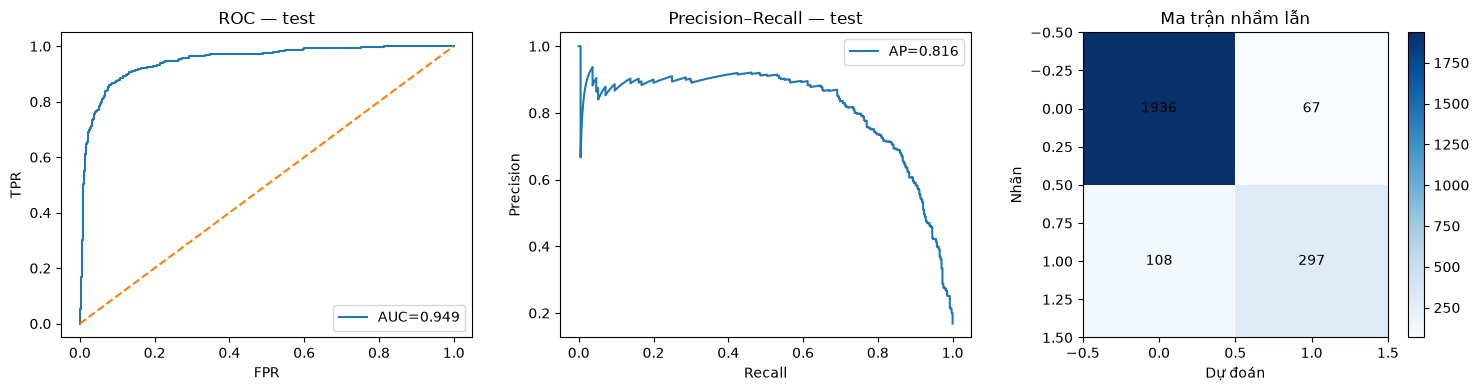

Khoảng bootstrap phân tầng 95% cho ROC-AUC (không tính thiết kế khảo sát): [0.9356934043379376, 0.9595319674808775]
Lưu ý: dữ liệu test đã từng được xem trong các lần chạy trước; đây không còn là kiểm định cuối hoàn toàn độc lập.


In [9]:
if selected.startswith('neural_seed_'):
    best_run=next(r for r in runs if selected==f"neural_seed_{r['seed']}")
    best_run['model'].eval()
    with torch.no_grad(): test_scores=torch.sigmoid(best_run['model'](torch.tensor(Xte))).numpy()
else: test_scores=candidates[selected].predict_proba(Xte)[:,1]
pred=(test_scores>=selected_threshold).astype(int)
test_metrics={**threshold_scores(yte,test_scores,selected_threshold),
    'accuracy':float(accuracy_score(yte,pred)),'brier':float(brier_score_loss(yte,test_scores)),
    'confusion_matrix':confusion_matrix(yte,pred,labels=[0,1]).tolist()}
print('Kết quả test CHỈ của ứng viên được chọn:'); print(json.dumps(test_metrics,indent=2))
print('Báo cáo phân loại:');print(classification_report(yte,pred,zero_division=0))
fpr,tpr,_=roc_curve(yte,test_scores); prec,rec,_=precision_recall_curve(yte,test_scores)
fig,axes=plt.subplots(1,3,figsize=(15,4))
axes[0].plot(fpr,tpr,label=f"AUC={test_metrics['roc_auc']:.3f}");axes[0].plot([0,1],[0,1],'--');axes[0].set(xlabel='FPR',ylabel='TPR',title='ROC — test');axes[0].legend()
axes[1].plot(rec,prec,label=f"AP={test_metrics['pr_auc']:.3f}");axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision–Recall — test');axes[1].legend()
cm=np.array(test_metrics['confusion_matrix']); im=axes[2].imshow(cm,cmap='Blues'); axes[2].set(xlabel='Dự đoán',ylabel='Nhãn',title='Ma trận nhầm lẫn')
for (i,j),value in np.ndenumerate(cm): axes[2].text(j,i,str(value),ha='center',va='center')
fig.colorbar(im,ax=axes[2]);plt.tight_layout();plt.show()
# Bootstrap phân tầng, cố định số lượng mỗi lớp: khoảng mô tả có điều kiện theo mẫu test.
rng=np.random.default_rng(SEED); neg=np.flatnonzero(yte==0); pos=np.flatnonzero(yte==1)
bootstrap=[]
for _ in range(10 if SMOKE else 100):
    ix=np.concatenate([rng.choice(neg,len(neg),replace=True),rng.choice(pos,len(pos),replace=True)])
    bootstrap.append(roc_auc_score(yte[ix],test_scores[ix]))
auc_ci=np.quantile(bootstrap,[.025,.975]).tolist()
print('Khoảng bootstrap phân tầng 95% cho ROC-AUC (không tính thiết kế khảo sát):',auc_ci)
print('Lưu ý: dữ liệu test đã từng được xem trong các lần chạy trước; đây không còn là kiểm định cuối hoàn toàn độc lập.')

## 10. Lưu model, cấu hình và kết quả
Lưu cả ba baseline, ba seed mạng, đường loss, lựa chọn, ngưỡng, các chỉ số và hash. Không tự thay thế model website.

In [10]:
def file_sha256(path):
    digest=hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda:stream.read(1024*1024),b''): digest.update(chunk)
    return digest.hexdigest()
hashes={str(p.relative_to(ROOT)):file_sha256(p) for p in source_paths}
run_info=[{k:r[k] for k in ['seed','best_epoch','epochs_run','updates','stopped_early','val_auc','history']} for r in runs]
report={'experiment':EXPERIMENT,'purpose':PURPOSE,'model_type':MODEL_TYPE,'smoke_test':SMOKE,
 'source_sha256':hashes,'features':features,'sizes':{'train':len(train),'validation':len(val),'test':len(test)},
 'class_counts':{name:{str(k):int(v) for k,v in frame['class'].value_counts().items()} for name,frame in [('train',train),('validation',val),('test',test)]},
 'training_config':{'seeds':seeds,'max_epochs':max_epochs,'min_epochs':min_epochs,'patience':patience_limit,'batch_size':batch_size,'learning_rate':.001},
 'neural_runs':run_info,'validation_metrics':validation_table.to_dict(orient='index'),
 'selection_rule':'highest validation ROC-AUC; ties favor baseline order; threshold max F1 on validation',
 'selected_model':selected,'selected_threshold':selected_threshold,'test_selected_only':test_metrics,'test_auc_bootstrap_stratified_95':auc_ci,
 'libraries':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__,'torch':torch.__version__},
 'warning':'Educational retrospective experiment, test previously inspected; not a clinical or Vietnamese validation.'}
(RUN_DIR/'report.json').write_text(json.dumps(report,indent=2,ensure_ascii=False)+'\n',encoding='utf-8')
joblib.dump(preprocessor,RUN_DIR/'preprocessor.joblib')
for name,est in candidates.items(): joblib.dump(est,RUN_DIR/f'{name}.joblib')
for run in runs: torch.save({'state_dict':run['model'].state_dict(),'input_size':Xtr.shape[1],'architecture':MODEL_TYPE,'seed':run['seed']},RUN_DIR/f"neural_seed_{run['seed']}.pt")
print('Lưu artifact:',RUN_DIR)

Lưu artifact: /app/artifacts/notebook_runs/nhanes4/20261105T081915_164118Z


## 11. Diễn giải
Kết quả là thử nghiệm trên tập dữ liệu cụ thể; có thể có sai lệch chọn mẫu, dữ liệu thiếu và khác biệt dân số. Cần kiểm định độc lập, hiệu chỉnh và thẩm định y khoa trước ứng dụng thực tế.